In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/netflix_clean.csv", parse_dates=["date_added"])
by_release = df.groupby("release_year").size()
print(by_release.index.min(), by_release.index.max(), len(by_release))
print(by_release.tail(15))

1925 2021 74
release_year
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     351
2015     555
2016     901
2017    1030
2018    1144
2019    1029
2020     953
2021     592
dtype: int64


In [2]:
all_years = range(by_release.index.min(), by_release.index.max() + 1)
missing_years = sorted(set(all_years) - set(by_release.index))
print(len(missing_years), missing_years[:10])
print(by_release.loc[:1999].sum(), by_release.loc[2000:].sum())

23 [1926, 1927, 1928, 1929, 1930, 1931, 1932, 1933, 1934, 1935]
525 8261


In [3]:
recent = df[df["release_year"] >= 2000]
trend = recent.groupby(["release_year", "type"]).size().unstack(fill_value=0)
trend["Total"] = trend.sum(axis=1)
trend["yoy_change_%"] = (trend["Total"].pct_change() * 100).round(1)
print(trend.tail(12))
print(trend["Total"].sum(), trend["Total"].idxmax())

type          Movie  TV Show  Total  yoy_change_%
release_year                                     
2010            153       39    192          26.3
2011            145       40    185          -3.6
2012            173       63    236          27.6
2013            225       61    286          21.2
2014            263       88    351          22.7
2015            396      159    555          58.1
2016            658      243    901          62.3
2017            765      265   1030          14.3
2018            766      378   1144          11.1
2019            632      397   1029         -10.1
2020            517      436    953          -7.4
2021            277      315    592         -37.9
8261 2018


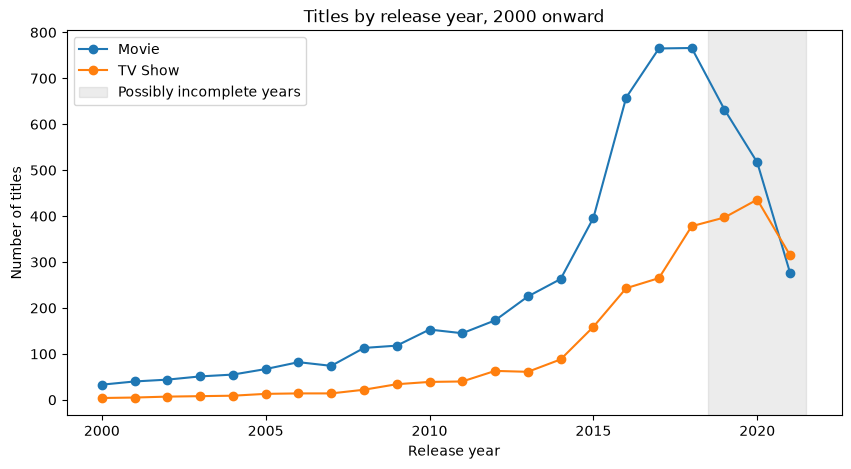

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(trend.index, trend["Movie"], marker="o", label="Movie")
plt.plot(trend.index, trend["TV Show"], marker="o", label="TV Show")
plt.axvspan(2018.5, 2021.5, alpha=0.15, color="gray", label="Possibly incomplete years")
plt.title("Titles by release year, 2000 onward")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.legend()
plt.show()

In [5]:
import numpy as np

series = trend.loc[2000:2018, "Total"]
train = series.loc[:2015]
test = series.loc[2016:]
print(len(train), len(test))

16 3


In [6]:
x_train = train.index.values - 2000
x_test = test.index.values - 2000

line = np.polyfit(x_train, train.values, 1)
pred_line = np.polyval(line, x_test)

expo = np.polyfit(x_train, np.log(train.values), 1)
pred_exp = np.exp(np.polyval(expo, x_test))

pred_naive = np.full(len(test), train.iloc[-1])

results = pd.DataFrame({"actual": test.values,
                        "naive": pred_naive.round(0),
                        "linear": pred_line.round(0),
                        "exponential": pred_exp.round(0)}, index=test.index)
print(results)

for name in ["naive", "linear", "exponential"]:
    print(name, "average error:", np.abs(results["actual"] - results[name]).mean().round(1), "titles")

              actual  naive  linear  exponential
release_year                                    
2016             901    555   383.0        493.0
2017            1030    555   408.0        581.0
2018            1144    555   434.0        685.0
naive average error: 470.0 titles
linear average error: 616.7 titles
exponential average error: 438.7 titles
